# 04 — BB84: distribución cuántica de claves

**Curso ECCI 2026 · Computación cuántica**

Todo lo anterior fue física. Este notebook es el único donde la física se
convierte en un producto: **el primer protocolo cuántico que se vendió**.

La idea de Bennett y Brassard (1984) es dar vuelta lo que hasta ahora fue un
obstáculo. En el `01b` vimos que medir en la base equivocada destruye
información; en el `03`, que un estado desconocido no se puede clonar. Las
dos
cosas son limitaciones molestas... salvo que quieras que **nadie pueda
copiar
lo que se manda**. Ahí son exactamente lo que se necesita.

La promesa de BB84 es fuerte, y su enunciado preciso es este:

> Espiar la clave **deja marcas detectables**, y esas marcas no se pueden >
evitar: son consecuencia de los postulados de la mecánica cuántica, no de la
> tecnología del espía.

Recorrido:

1. El problema de la distribución de claves.
2. El protocolo, paso a paso.
3. Sin Eve: la criba de bases y QBER ≈ 0.
4. **Con Eve**: por qué el QBER salta a 25 %, con la cuenta.
5. Estadística sobre muchas corridas: dos poblaciones separadas.
6. Eve parcial: el QBER como termómetro.
7. Hardware real, donde **el ruido del chip es indistinguible de un espía**.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
rng = np.random.default_rng(20260917)
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. El problema

Cifrar un mensaje es fácil si Alice y Bob ya comparten una clave secreta.
Con
una clave **tan larga como el mensaje, usada una sola vez** (el *one-time
pad*), el cifrado es **demostrablemente irrompible**: Shannon lo probó en
1949.
El texto cifrado no contiene absolutamente ninguna información sobre el
mensaje.

El problema nunca fue cifrar. Es **cómo se ponen de acuerdo en la clave**
sin
que un tercero la vea.

La criptografía clásica lo resuelve con problemas computacionalmente duros
—RSA con factorización, Diffie-Hellman con logaritmos discretos— y eso deja
dos flancos abiertos:

1. **Nadie demostró que sean duros.** Un avance en teoría de números podría
   romperlos mañana.
2. **Shor los rompe** (notebook `09`), cuando haya hardware. Y hay una
amenaza
   concreta hoy: *store now, decrypt later* — guardar tráfico cifrado ahora
   para descifrarlo en veinte años.

BB84 no se apoya en dureza computacional. Se apoya en que **medir
perturba**,
que no es una conjetura.

---
# 2. El protocolo

Alice y Bob tienen un **canal cuántico** (fibra, o el aire) y un **canal
clásico público autenticado** (internet: cualquiera lo escucha, pero nadie
puede hacerse pasar por otro).

**Por cada bit de clave candidata:**

| paso | quién | qué hace |
|---|---|---|
| 1 | Alice | elige un **bit** al azar (0 o 1) y una **base** al azar (Z o X) |
| 2 | Alice | prepara el qubit correspondiente y lo manda |
| 3 | Bob | elige una **base** al azar, mide, anota |

Los cuatro estados posibles son:

| bit | base Z | base X |
|---|---|---|
| 0 | $\|0\rangle$ | $\|+\rangle$ |
| 1 | $\|1\rangle$ | $\|-\rangle$ |

**Después, por el canal público:**

| paso | qué |
|---|---|
| 4 | anuncian las **bases** (nunca los bits) y descartan las rondas donde no coincidieron: la **criba**. Sobrevive ~50 % |
| 5 | sacrifican una muestra al azar de las que quedan y comparan **bits**: eso da el **QBER** |
| 6 | si el QBER es bajo, el resto es la clave. Si es alto, **abortan** |

### Por qué funciona

Los cuatro estados **no son mutuamente ortogonales**: $|0\rangle$ y
$|+\rangle$ tienen solapamiento $1/\sqrt2$. Y estados no ortogonales **no se
pueden distinguir con certeza**, ni clonar. Eve no tiene ninguna estrategia
que le dé información sin perturbar: es un teorema, no una limitación
técnica.

La visualización del `01` sirve acá tal cual: los cuatro estados son cuatro
puntos sobre el ecuador y el eje $z$ de la esfera de Bloch, y medir en la
base
equivocada es preguntarle a un punto del ecuador cuánto vale su $z$.

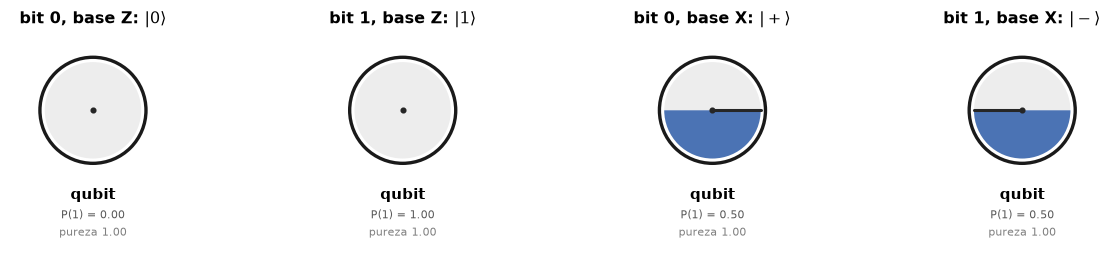

Solapamientos entre estados de bases distintas:
  |⟨$|0\rangle$|$|+\rangle$⟩| = 0.7071
  |⟨$|0\rangle$|$|-\rangle$⟩| = 0.7071
  |⟨$|1\rangle$|$|+\rangle$⟩| = 0.7071
  |⟨$|1\rangle$|$|-\rangle$⟩| = 0.7071

Ninguno es 0: no son ortogonales, así que no se distinguen con certeza.


In [4]:
def preparar(bit: int, base: int) -> QuantumCircuit:
    """base 0 = Z (|0>,|1>), base 1 = X (|+>,|->)."""
    qc = QuantumCircuit(1)
    if bit:
        qc.x(0)
    if base:
        qc.h(0)
    return qc


fig, ejes = plt.subplots(1, 4, figsize=(12, 2.5))
etiquetas = [(0, 0, r"bit 0, base Z: $|0\rangle$"), (1, 0, r"bit 1, base Z: $|1\rangle$"),
             (0, 1, r"bit 0, base X: $|+\rangle$"), (1, 1, r"bit 1, base X: $|-\rangle$")]
for ax, (bit, base, txt) in zip(ejes, etiquetas):
    utils.discos_qubits(Statevector(preparar(bit, base)), ax=ax, etiquetas=["qubit"],
                        titulo=txt)
utils.layout(fig)
plt.show()

utils.bloch_plotly({t: utils.bloch_de_estado(preparar(b, ba))
                    for b, ba, t in [(0, 0, "|0⟩ (bit 0, Z)"), (1, 0, "|1⟩ (bit 1, Z)"),
                                     (0, 1, "|+⟩ (bit 0, X)"), (1, 1, "|−⟩ (bit 1, X)")]},
                   titulo="Los cuatro estados de BB84: dos bases no ortogonales",
                   tamano=470).show()

print("Solapamientos entre estados de bases distintas:")
for (b1, ba1, t1) in etiquetas[:2]:
    for (b2, ba2, t2) in etiquetas[2:]:
        s = abs(Statevector(preparar(b1, ba1)).inner(Statevector(preparar(b2, ba2))))
        print(f"  |⟨{t1.split(': ')[1]}|{t2.split(': ')[1]}⟩| = {s:.4f}")
print("\nNinguno es 0: no son ortogonales, así que no se distinguen con certeza.")

---
# 3. Una ronda, como circuito

Cada ronda es un qubit. Con Eve en el medio son tres mediciones; sin ella,
dos.

Ronda con Eve: Alice prepara (bit 1, base X), Eve mide en Z, Bob mide en X


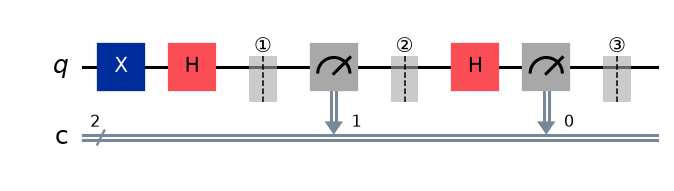

In [5]:
def ronda(bit_a: int, base_a: int, base_b: int, eve: bool = False,
          base_e: int = 0) -> QuantumCircuit:
    """Una ronda completa de BB84.

    Bits clásicos: c0 = Bob.  Si hay Eve, c1 = Eve.
    """
    qc = QuantumCircuit(1, 2 if eve else 1)

    if bit_a:                       # Alice prepara
        qc.x(0)
    if base_a:
        qc.h(0)
    marca(qc, 1)

    if eve:                         # Eve intercepta, mide y reenvía
        if base_e:
            qc.h(0)
        qc.measure(0, 1)
        if base_e:
            qc.h(0)
        marca(qc, 2)

    if base_b:                      # Bob mide
        qc.h(0)
    qc.measure(0, 0)
    marca(qc, 3 if eve else 2)
    return qc


print("Ronda con Eve: Alice prepara (bit 1, base X), Eve mide en Z, Bob mide en X")
display(ronda(1, 1, 1, eve=True, base_e=0).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa (bit 1, base X; Eve mide en Z; Bob mide en X)

**①** Alice preparó $|\psi_1\rangle = |-\rangle$. Si Eve no existiera, Bob
—que mide en X— obtendría el bit 1 con certeza.

**②** Dado que Eve mide en Z sobre $|-\rangle = (|0\rangle -
|1\rangle)/\sqrt2$:
obtiene 0 o 1 con probabilidad $1/2$ cada uno, **sin ninguna información
útil**, y el estado colapsa a $|0\rangle$ o $|1\rangle$. Eve reenvía eso.

**③** Dado que Bob mide en X sobre $|0\rangle$ (o $|1\rangle$), que en la
base
X es $(|+\rangle \pm |-\rangle)/\sqrt2$: obtiene 0 o 1 con probabilidad
$1/2$.

**Alice mandó un 1 y Bob lee 1 solo la mitad de las veces.** Esa ronda
—donde
las bases de Alice y Bob coincidían y debería haber sido perfecta— tiene
ahora
50 % de error. Y Eve no se llevó nada: su resultado en Z no dice nada sobre
un
estado que estaba en X.

---
# 4. El protocolo completo

### Una decisión de implementación, y por qué

Cada ronda de BB84 usa **un qubit**, y las rondas son independientes. Se
podría simular una por circuito, pero es mala idea: Aer paga un costo fijo
por
circuito, y 200 circuitos de un qubit tardan ~14 s mientras que **el mismo
experimento como un único circuito de 200 qubits tarda ~1.8 s**.

Así que armamos **un circuito con una ronda por qubit**, y usamos los
*shots*
como corridas independientes del protocolo. Es exactamente la misma
estructura
que se manda a hardware en §7, donde el ahorro importa todavía más porque el
overhead por job domina el costo de QPU.

In [6]:
def bb84_paralelo(bits_a, bases_a, bases_b, bases_e=None, intercepta=None):
    """n rondas de BB84, una por qubit, en un solo circuito.

    Bits clásicos: los n primeros son Bob; si hay Eve, los n siguientes son Eve.
    """
    n = len(bits_a)
    hay_eve = intercepta is not None and any(intercepta)
    qc = QuantumCircuit(n, 2 * n if hay_eve else n)

    for i in range(n):                      # Alice prepara
        if bits_a[i]:
            qc.x(i)
        if bases_a[i]:
            qc.h(i)
    marca(qc, 1)

    if hay_eve:                             # Eve intercepta y reenvía
        for i in range(n):
            if intercepta[i]:
                if bases_e[i]:
                    qc.h(i)
                qc.measure(i, n + i)
                if bases_e[i]:
                    qc.h(i)
        marca(qc, 2)

    for i in range(n):                      # Bob mide
        if bases_b[i]:
            qc.h(i)
        qc.measure(i, i)
    marca(qc, 3 if hay_eve else 2)
    return qc


_NM = {}


def correr_bb84(n_rondas: int, n_corridas: int = 1, eve: bool = False,
                p_eve: float = 1.0, ruido: bool = False, rng=None) -> dict:
    """Simula n_corridas del protocolo, con n_rondas cada una.

    Cada shot del circuito es una corrida independiente: las bases y los bits de
    Alice quedan fijos, y lo que cambia de shot a shot es el azar de las
    mediciones (y el de Eve, si está).
    """
    from qiskit import transpile
    from qiskit_aer import AerSimulator

    rng = rng or np.random.default_rng()
    bits_a = rng.integers(0, 2, n_rondas)
    bases_a = rng.integers(0, 2, n_rondas)
    bases_b = rng.integers(0, 2, n_rondas)
    bases_e = rng.integers(0, 2, n_rondas)
    intercepta = (rng.random(n_rondas) < p_eve) if eve else np.zeros(n_rondas, bool)

    qc = bb84_paralelo(bits_a, bases_a, bases_b, bases_e, intercepta)
    if ruido:
        from qiskit_aer.noise import NoiseModel
        if "nm" not in _NM:
            _NM["nm"] = NoiseModel.from_backend(fez)
        nm = _NM["nm"]
        sim = AerSimulator(noise_model=nm, method="matrix_product_state")
        tq = transpile(qc, basis_gates=nm.basis_gates, optimization_level=1)
    else:
        sim = AerSimulator(method="matrix_product_state")
        tq = qc            # h, x y measure ya son nativas de Aer: no hay nada
                           # que transpilar, y transpilar contra el simulador
                           # falla arriba de 63 qubits por su coupling map
    memoria = sim.run(tq, shots=n_corridas, memory=True).result().get_memory()

    # cada cadena viene little-endian: el bit clásico i está en la posición -1-i
    bits_b = np.array([[int(m.replace(" ", "")[::-1][i]) for i in range(n_rondas)]
                       for m in memoria])
    coinciden = bases_a == bases_b
    return {"bits_a": bits_a, "bases_a": bases_a, "bases_b": bases_b,
            "bases_e": bases_e, "bits_b": bits_b, "coinciden": coinciden,
            "intercepta": intercepta}


def qber_por_corrida(res) -> np.ndarray:
    """Tasa de error de cada corrida, sobre las rondas que sobrevivieron la criba."""
    m = res["coinciden"]
    if m.sum() == 0:
        return np.array([np.nan])
    return (res["bits_b"][:, m] != res["bits_a"][m]).mean(axis=1)


N_RONDAS, N_CORRIDAS = 256, 120
sin_eve = correr_bb84(N_RONDAS, N_CORRIDAS, eve=False, rng=np.random.default_rng(1))
con_eve = correr_bb84(N_RONDAS, N_CORRIDAS, eve=True, rng=np.random.default_rng(1))

q_sin, q_con = qber_por_corrida(sin_eve), qber_por_corrida(con_eve)
print(f"{'':<26} {'sin Eve':>14} {'con Eve':>14}")
print(f"{'rondas por corrida':<26} {N_RONDAS:>14} {N_RONDAS:>14}")
print(f"{'bases coincidentes':<26} {sin_eve['coinciden'].sum():>14} "
      f"{con_eve['coinciden'].sum():>14}")
print(f"{'QBER medio':<26} {q_sin.mean():>14.4f} {q_con.mean():>14.4f}")
print(f"{'QBER esperado':<26} {0.0:>14.4f} {0.25:>14.4f}")

                                  sin Eve        con Eve
rondas por corrida                    256            256
bases coincidentes                    141            141
QBER medio                         0.0000         0.2402
QBER esperado                      0.0000         0.2500


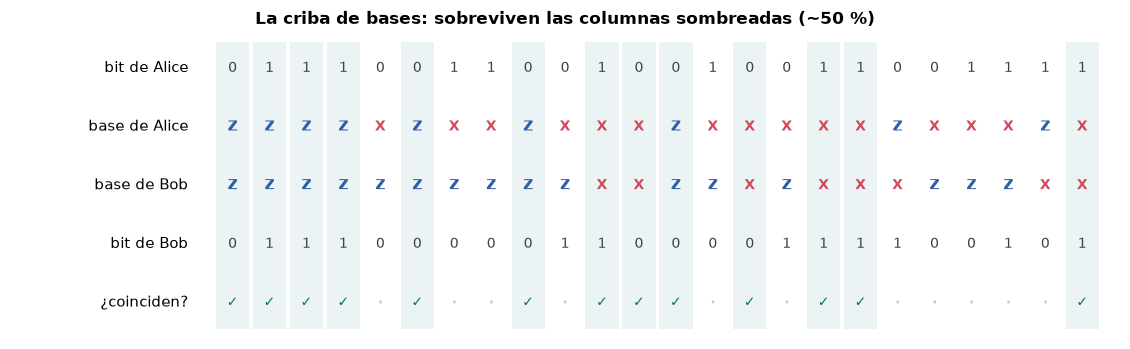

clave de Alice (primeros 40): 0111001000111110000000101011100100000001
clave de Bob   (primeros 40): 0111001000111110000000101011100100000001
¿idénticas? True   (141 bits de 256 rondas = 55%)


In [7]:
n_ver = 24
fig, ax = plt.subplots(figsize=(13, 3.6))
filas = [
    ("bit de Alice", sin_eve["bits_a"][:n_ver], "bits"),
    ("base de Alice", sin_eve["bases_a"][:n_ver], "bases"),
    ("base de Bob", sin_eve["bases_b"][:n_ver], "bases"),
    ("bit de Bob", sin_eve["bits_b"][0][:n_ver], "bits"),
    ("¿coinciden?", sin_eve["coinciden"][:n_ver].astype(int), "criba"),
]
for i, (nombre, datos, tipo) in enumerate(filas):
    y = len(filas) - 1 - i
    for j, v in enumerate(datos):
        if tipo == "bases":
            txt, color = ("Z", utils.COLOR_IDEAL) if v == 0 else ("X", utils.COLOR_RUIDO)
        elif tipo == "criba":
            txt, color = ("✓", utils.COLOR_HARD) if v else ("·", "0.8")
        else:
            txt, color = str(v), "0.25"
        ax.text(j, y, txt, ha="center", va="center", fontsize=9, color=color,
                fontweight="bold" if tipo != "bits" else "normal")
    ax.text(-1.2, y, nombre, ha="right", va="center", fontsize=9.5)
for j in range(n_ver):
    if sin_eve["coinciden"][j]:
        ax.add_patch(plt.Rectangle((j - 0.45, -0.45), 0.9, len(filas) - 0.1,
                                   color=utils.COLOR_HARD, alpha=0.08, lw=0))
ax.set_xlim(-6, n_ver)
ax.set_ylim(-0.6, len(filas) - 0.4)
ax.axis("off")
ax.set_title("La criba de bases: sobreviven las columnas sombreadas (~50 %)",
             fontweight="bold")
plt.show()

clave_a = sin_eve["bits_a"][sin_eve["coinciden"]]
clave_b = sin_eve["bits_b"][0][sin_eve["coinciden"]]
print(f"clave de Alice (primeros 40): {''.join(map(str, clave_a[:40]))}")
print(f"clave de Bob   (primeros 40): {''.join(map(str, clave_b[:40]))}")
print(f"¿idénticas? {np.array_equal(clave_a, clave_b)}   "
      f"({len(clave_a)} bits de {N_RONDAS} rondas = {len(clave_a) / N_RONDAS:.0%})")

---
# 5. Por qué Eve deja el 25 %

La estrategia más simple de Eve es **interceptar y reenviar**: mide cada
qubit
en una base al azar y manda a Bob lo que le dio.

La cuenta, condicionada a que Alice y Bob usaron la **misma** base —que son
las únicas rondas que importan, porque las otras se descartan:

| caso | probabilidad | error de Bob |
|---|---|---|
| Eve eligió **la misma** base que Alice | $1/2$ | 0 — leyó bien y reenvió el estado correcto |
| Eve eligió **la otra** base | $1/2$ | $1/2$ — el estado quedó rotado y Bob tira una moneda |

$$\text{QBER} = \frac12 \cdot 0 + \frac12 \cdot \frac12 = \boxed{\;25\%\;}$$

Y el 25 % es lo que Eve paga por espiar **todo**. Si intercepta solo una
fracción $p$, el QBER es $0.25\,p$ — y su información baja en la misma
proporción. **No hay espionaje gratis.**

Podemos verificar el desglose, porque en la simulación sabemos qué base
eligió
Eve en cada ronda. Alice y Bob, por supuesto, no.

In [8]:
cribadas = con_eve["coinciden"]
acierta_e = con_eve["bases_e"] == con_eve["bases_a"]
errores = con_eve["bits_b"] != con_eve["bits_a"]

desglose = {}
for nombre, mascara in [("Eve acertó la base", cribadas & acierta_e),
                        ("Eve erró la base", cribadas & ~acierta_e)]:
    desglose[nombre] = errores[:, mascara].mean()
    print(f"{nombre:<22} {mascara.sum():>4} rondas   error de Bob = "
          f"{desglose[nombre]:.4f}")
print(f"\nQBER total = {q_con.mean():.4f}   (predicción: 0.2500)")

Eve acertó la base       73 rondas   error de Bob = 0.0000
Eve erró la base         68 rondas   error de Bob = 0.4982

QBER total = 0.2402   (predicción: 0.2500)


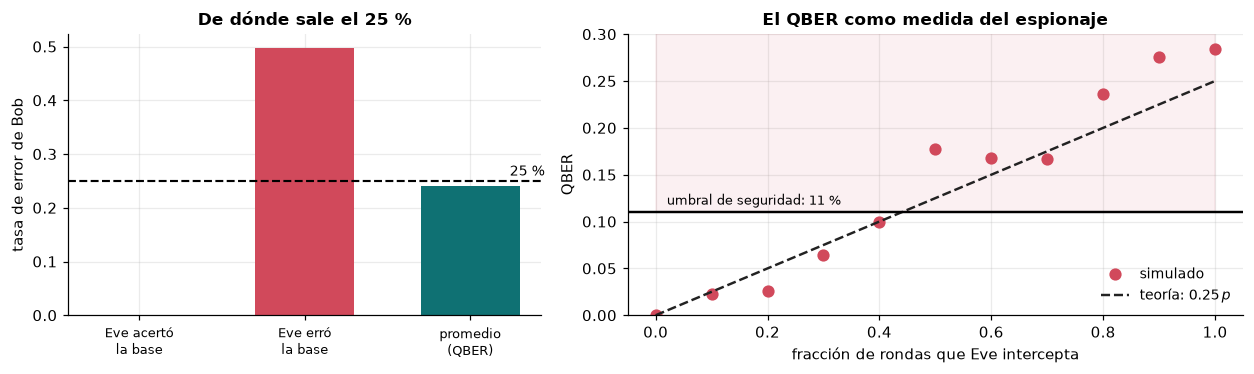

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.5),
                               gridspec_kw={"width_ratios": [1, 1.3]})
ax1.bar([0, 1, 2], [desglose["Eve acertó la base"], desglose["Eve erró la base"],
                    q_con.mean()],
        color=[utils.COLOR_IDEAL, utils.COLOR_RUIDO, utils.COLOR_HARD], width=0.6)
ax1.axhline(0.25, color="k", ls="--", lw=1.4)
ax1.text(2.45, 0.26, "25 %", ha="right", fontsize=9)
ax1.set_xticks([0, 1, 2])
ax1.set_xticklabels(["Eve acertó\nla base", "Eve erró\nla base", "promedio\n(QBER)"],
                    fontsize=8.5)
ax1.set_ylabel("tasa de error de Bob")
ax1.set_title("De dónde sale el 25 %")

ps = np.linspace(0, 1, 11)
qbers = []
for i, p in enumerate(ps):
    r = correr_bb84(256, 40, eve=p > 0, p_eve=float(p),
                    rng=np.random.default_rng(100 + i))
    qbers.append(qber_por_corrida(r).mean())
ax2.plot(ps, qbers, "o", ms=7, color=utils.COLOR_RUIDO, label="simulado")
ax2.plot(ps, 0.25 * ps, "--", color=utils.COLOR_TEORIA, lw=1.6,
         label=r"teoría: $0.25\,p$")
ax2.axhline(0.11, color="k", lw=1.6)
ax2.text(0.02, 0.118, "umbral de seguridad: 11 %", fontsize=8.5)
ax2.fill_between([0, 1], 0.11, 0.3, color=utils.COLOR_RUIDO, alpha=0.08)
ax2.set_xlabel("fracción de rondas que Eve intercepta")
ax2.set_ylabel("QBER")
ax2.set_ylim(0, 0.3)
ax2.set_title("El QBER como medida del espionaje")
ax2.legend(fontsize=9)
utils.layout(fig)
plt.show()

**La línea del 11 % es el número que usa la industria.** No es arbitrario:
arriba de ese QBER, la información que Eve pudo haberse llevado supera a la
que Alice y Bob pueden recuperar con corrección de errores y amplificación
de
privacidad, y el protocolo aborta. Sale de la cota de Shor-Preskill (2000).

La recta implica algo incómodo: **una Eve prudente que intercepte solo el 20
%
de las rondas produce un QBER del 5 %, por debajo del umbral**, y se lleva
algo de información. Por eso el protocolo real no termina en la criba: sigue
con *amplificación de privacidad*, que comprime la clave hasta dejar a Eve
con
información despreciable, a costa de longitud.

---
# 6. Estadística: las dos poblaciones

Una sola corrida no prueba nada — el QBER fluctúa. Lo que hay que ver es la
**distribución** sobre muchas corridas.

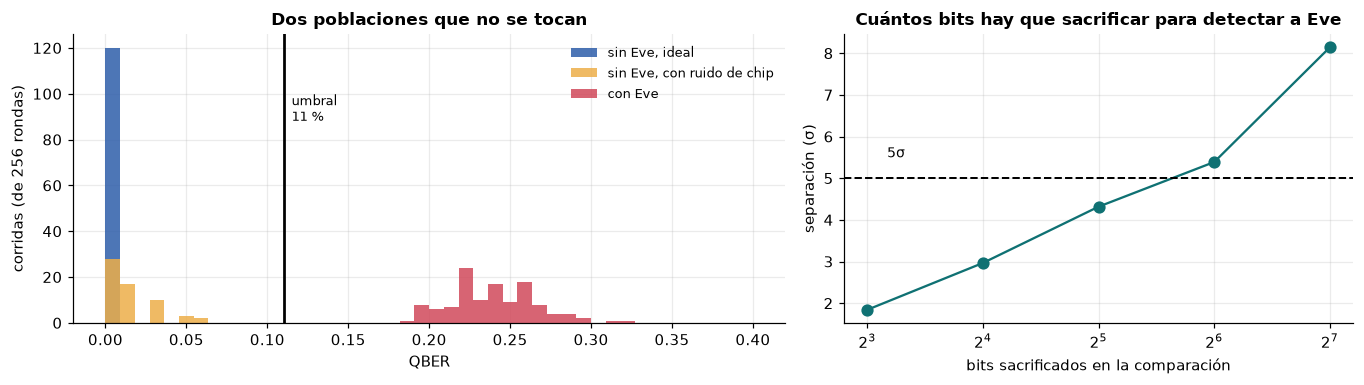

QBER sin Eve (ideal)    : 0.0000 ± 0.0000
QBER sin Eve (con ruido): 0.0143 ± 0.0168
QBER con Eve            : 0.2402 ± 0.0264


In [10]:
# El modelo de ruido define errores para los 156 qubits del chip, así que la
# corrida ruidosa usa menos rondas por circuito que la ideal.
ruidoso = correr_bb84(128, 60, eve=False, ruido=True,
                      rng=np.random.default_rng(77))
q_ruido = qber_por_corrida(ruidoso)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6),
                               gridspec_kw={"width_ratios": [1.4, 1]})
bins = np.linspace(0, 0.4, 45)
ax1.hist(q_sin, bins=bins, color=utils.COLOR_IDEAL, alpha=0.85, label="sin Eve, ideal")
ax1.hist(q_ruido, bins=bins, color=utils.PALETA[3], alpha=0.85,
         label="sin Eve, con ruido de chip")
ax1.hist(q_con, bins=bins, color=utils.COLOR_RUIDO, alpha=0.85, label="con Eve")
ax1.axvline(0.11, color="k", lw=1.8)
ax1.text(0.115, ax1.get_ylim()[1] * 0.7, "umbral\n11 %", fontsize=8.5)
ax1.set_xlabel("QBER")
ax1.set_ylabel(f"corridas (de {N_RONDAS} rondas)")
ax1.set_title("Dos poblaciones que no se tocan")
ax1.legend(fontsize=8.5)

tamanos = [8, 16, 32, 64, 128]
separacion = []
idx_crib = np.where(sin_eve["coinciden"])[0]
for t in tamanos:
    if len(idx_crib) < t:
        separacion.append(np.nan)
        continue
    idx = idx_crib[:t]
    e_sin = (sin_eve["bits_b"][:, idx] != sin_eve["bits_a"][idx]).mean(axis=1)
    e_con = (con_eve["bits_b"][:, idx] != con_eve["bits_a"][idx]).mean(axis=1)
    separacion.append((e_con.mean() - e_sin.mean()) / max(e_con.std(), 1e-9))
ax2.semilogx(tamanos, separacion, "o-", ms=7, color=utils.COLOR_HARD, base=2)
ax2.axhline(5, color="k", ls="--", lw=1.3)
ax2.text(9, 5.5, "5σ", fontsize=9)
ax2.set_xlabel("bits sacrificados en la comparación")
ax2.set_ylabel("separación (σ)")
ax2.set_title("Cuántos bits hay que sacrificar para detectar a Eve")
utils.layout(fig)
plt.show()

print(f"QBER sin Eve (ideal)    : {q_sin.mean():.4f} ± {q_sin.std():.4f}")
print(f"QBER sin Eve (con ruido): {q_ruido.mean():.4f} ± {q_ruido.std():.4f}")
print(f"QBER con Eve            : {q_con.mean():.4f} ± {q_con.std():.4f}")

**Las tres distribuciones cuentan la historia completa.** Sin Eve y sin
ruido,
el QBER es exactamente 0. Con Eve se planta en 0.25, y las dos poblaciones
no
se tocan.

El panel derecho responde la pregunta operativa: **¿cuántos bits hay que
sacrificar para estar seguros?** La separación entre las dos poblaciones
crece
con la raíz del tamaño de la muestra, y con unas pocas decenas de bits ya
pasa
de 5σ. La detección es barata.

La barra del medio —**sin Eve pero con el ruido de un chip real**— es la que
más enseña, y es el tema de §7.

### Para probar

In [11]:
def explorar_bb84(rondas=256, fraccion_eve=0.0, con_ruido=False):
    r = correr_bb84(int(rondas), 30, eve=float(fraccion_eve) > 0,
                    p_eve=float(fraccion_eve), ruido=bool(con_ruido),
                    rng=np.random.default_rng(int(rondas) + int(float(fraccion_eve) * 100)))
    qs = qber_por_corrida(r)
    n_clave = int(r["coinciden"].sum())
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    errores = (r["bits_b"][0][r["coinciden"]] != r["bits_a"][r["coinciden"]]).astype(int)
    acumulado = np.cumsum(errores) / np.arange(1, len(errores) + 1)
    ax.plot(acumulado, color=utils.COLOR_RUIDO, lw=1.8, label="QBER acumulado")
    ax.axhline(0.25 * float(fraccion_eve), color=utils.COLOR_TEORIA, ls="--", lw=1.4,
               label=f"teoría (solo Eve): {0.25 * float(fraccion_eve):.3f}")
    ax.axhline(0.11, color="k", lw=1.6, label="umbral 11 %")
    ax.set_xlabel("bits de clave comparados")
    ax.set_ylabel("QBER acumulado")
    ax.set_ylim(0, max(0.35, qs.mean() * 1.4))
    ax.set_title(f"QBER = {qs.mean():.4f} ± {qs.std():.4f} sobre {n_clave} bits"
                 f"   →   {'ABORTAR' if qs.mean() > 0.11 else 'clave aceptada'}")
    ax.legend(fontsize=8.5)
    plt.show()
    print(f"rondas {int(rondas)} · cribadas {n_clave} ({n_clave / int(rondas):.0%}) · "
          f"QBER {qs.mean():.4f} · "
          f"{'hay espía o ruido excesivo' if qs.mean() > 0.11 else 'canal limpio'}")


utils.deslizador(explorar_bb84, rondas=[64, 128, 256],
                 fraccion_eve=(0.0, 1.0, 0.1), con_ruido=[False, True])

interactive(children=(Dropdown(description='rondas', index=2, options=(64, 128, 256), value=256), FloatSlider(…

interactive(children=(Dropdown(description='rondas', index=2, options=(64, 128, 256), value=256), FloatSlider(…

---
# 7. Hardware real: el ruido es indistinguible de un espía

Este es el punto que convierte a BB84 de curiosidad en ingeniería.

**Alice y Bob no pueden saber si el QBER viene de Eve o del canal.** Un
detector imperfecto, una fibra con pérdidas, un chip con error de lectura
del
1 % — todo produce errores que se ven exactamente igual. Y como no pueden
distinguirlos, **la única postura segura es atribuirlos todos a Eve**.

Eso tiene una consecuencia dura y concreta: el ruido del canal **consume
presupuesto de seguridad**. Si tu hardware ya produce 8 % de QBER, te quedan
3 puntos antes del umbral, y la clave final después de la amplificación de
privacidad es cortísima.

Por eso la QKD comercial es, sobre todo, un problema de **fotónica de bajo
ruido**, no de protocolos. Y por eso correr BB84 en un chip superconductor
es
una demostración didáctica, no un producto: los qubits no viajan.

In [12]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [13]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


### Muchas rondas en un solo circuito

Cada ronda de BB84 usa **un qubit**, así que se pueden meter decenas de
rondas
en el mismo circuito, en qubits distintos (la técnica de `01b` §10.1). Con
40
rondas por circuito y 4 circuitos, salen 160 rondas por el precio de 4.

4 circuitos × 40 rondas = 160 rondas por shot
con 1024 shots: 163840 rondas en total, en un solo job


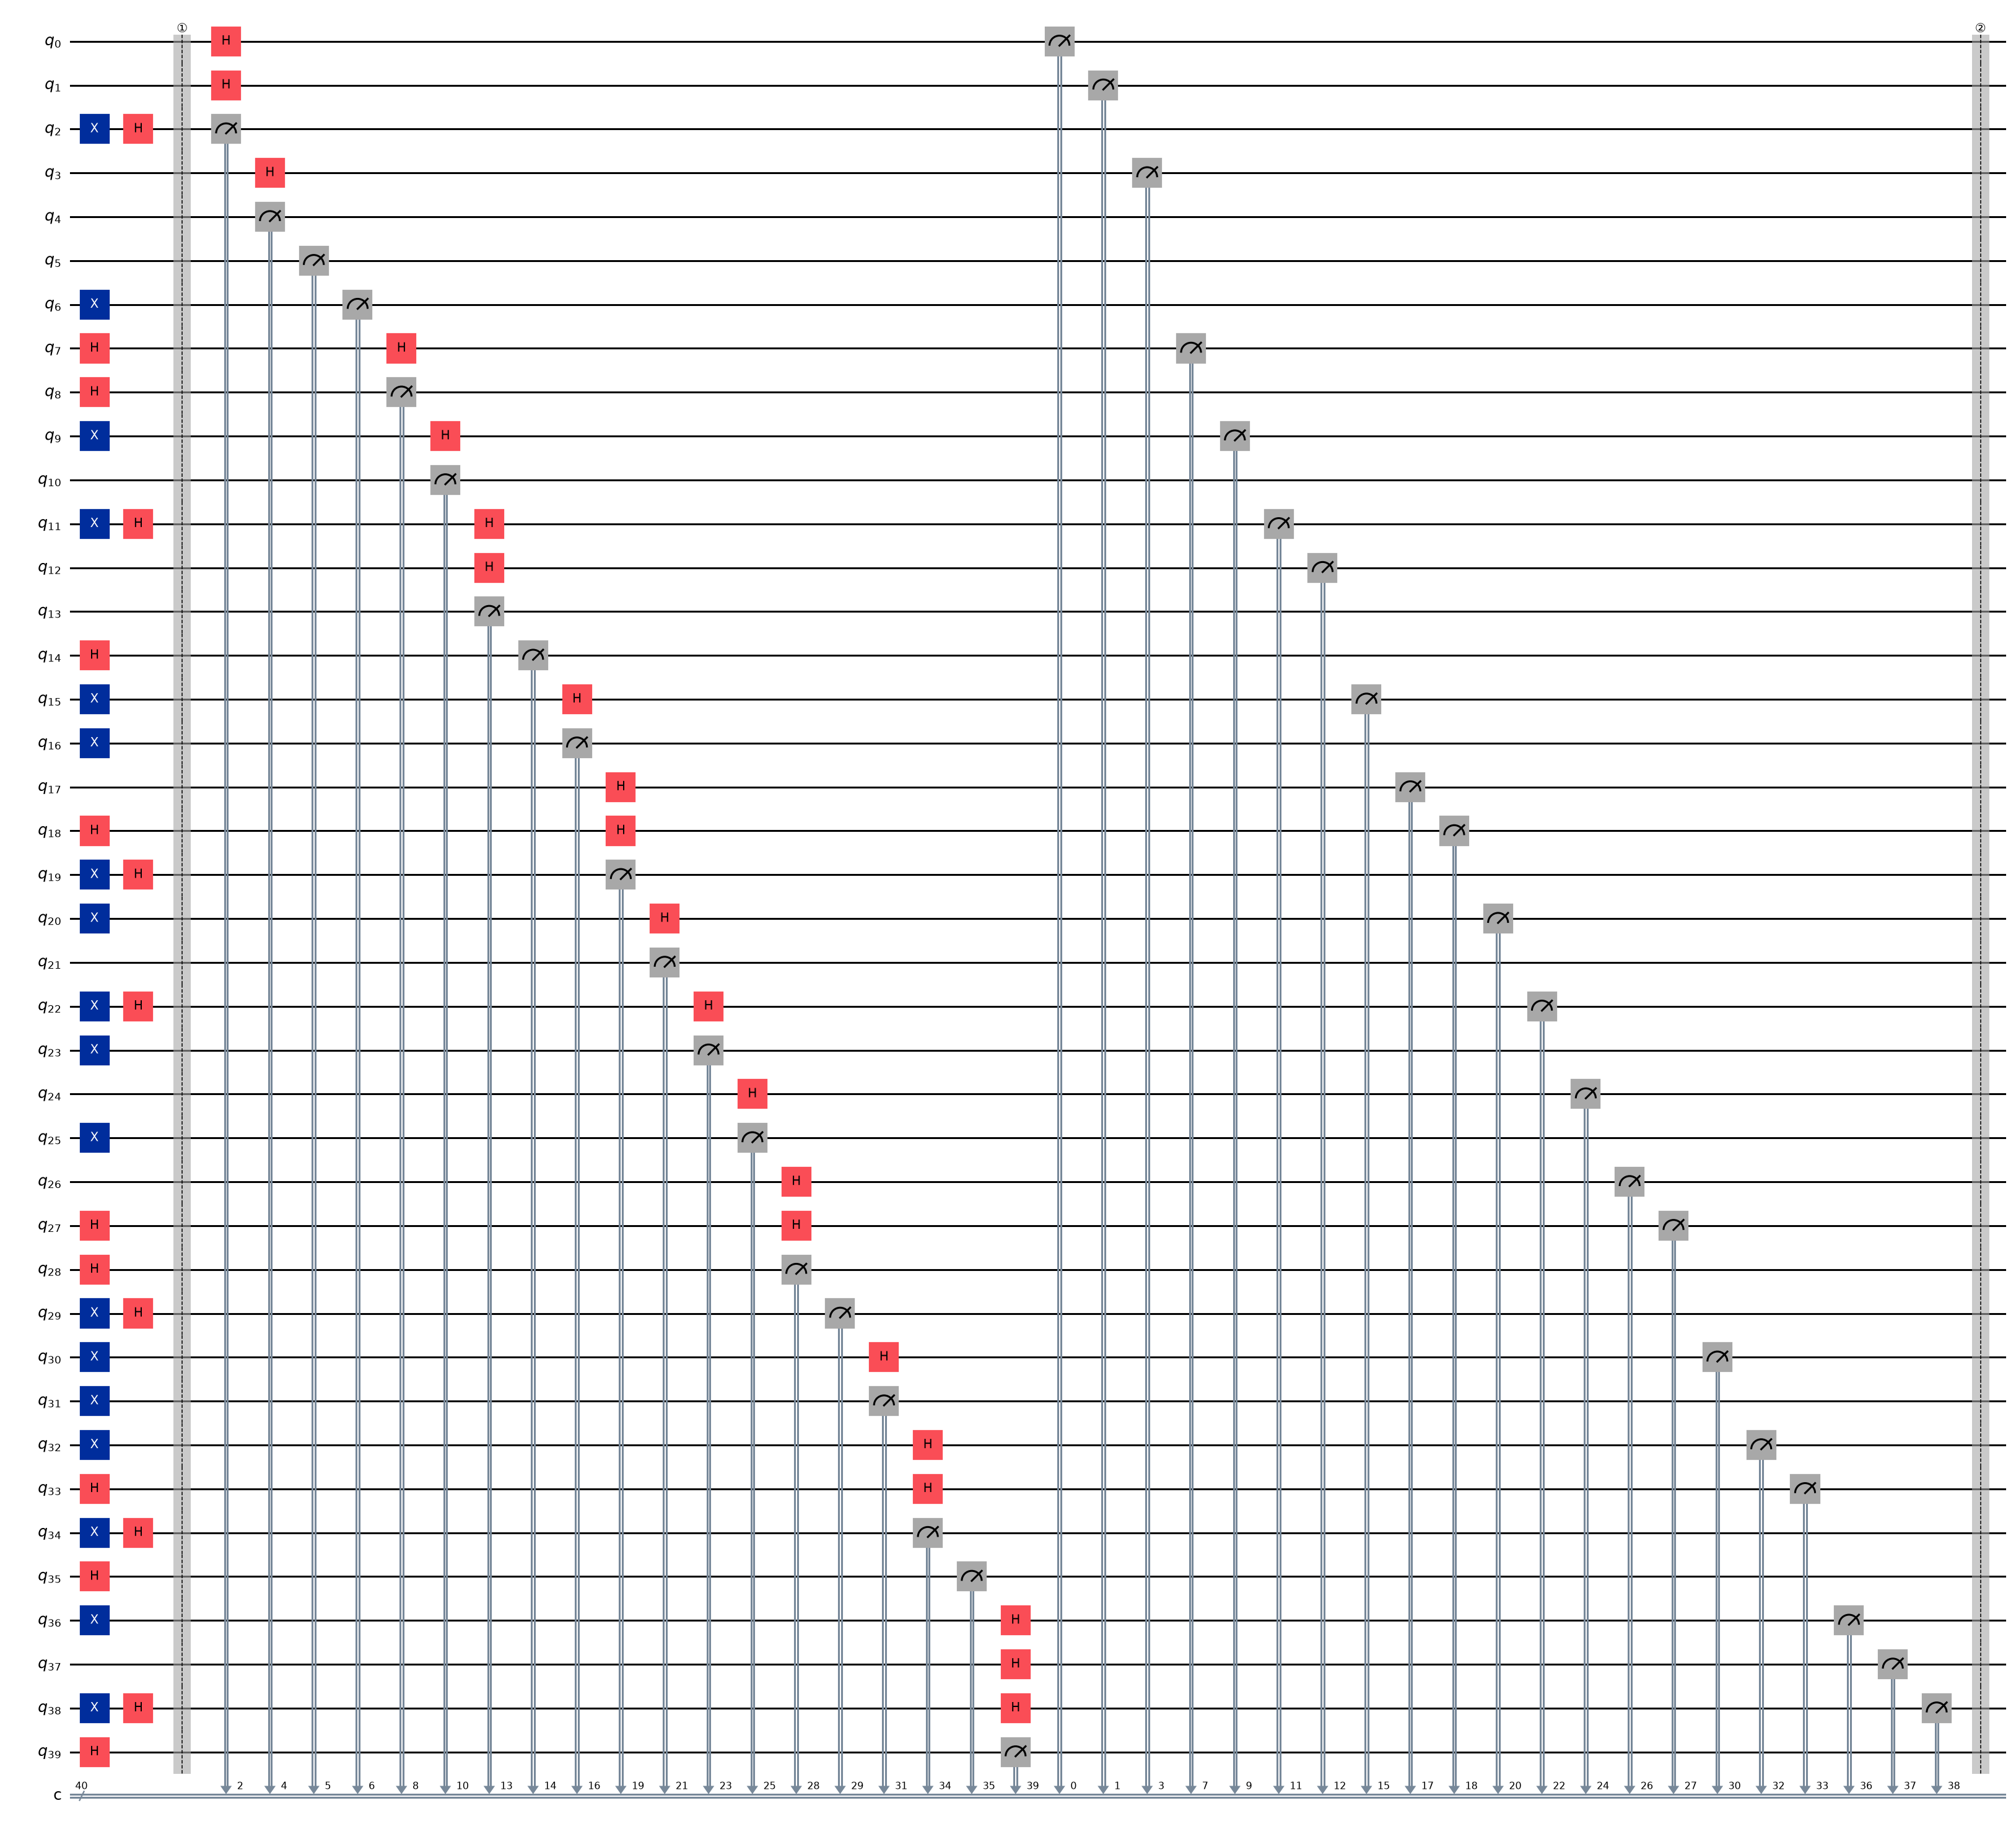

In [14]:
N_PAR, N_CIRC = 40, 4
SHOTS_HW = 1     # cada shot es una ronda independiente; con 1024 shots son 1024 rondas
rng_hw = np.random.default_rng(424242)
lotes = []
for _ in range(N_CIRC):
    ba = rng_hw.integers(0, 2, N_PAR)
    bsa = rng_hw.integers(0, 2, N_PAR)
    bsb = rng_hw.integers(0, 2, N_PAR)
    lotes.append((ba, bsa, bsb))

circuitos_hw = [bb84_paralelo(*l) for l in lotes]
print(f"{N_CIRC} circuitos × {N_PAR} rondas = {N_CIRC * N_PAR} rondas por shot")
print(f"con 1024 shots: {N_CIRC * N_PAR * 1024} rondas en total, en un solo job")
display(bb84_paralelo(*lotes[0]).draw("mpl", style="iqp", fold=-1))

In [15]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 1024
t_bb84 = None
if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_bb84 = pm.run(circuitos_hw)
    print("=== BB84 en paralelo ===")
    costo = utils.informe_transpilacion(t_bb84, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


In [16]:
ENVIAR_BB84 = False   # ponerlo en True para gastar QPU

if ENVIAR_BB84:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_bb84, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"04 BB84: {N_CIRC}x{N_PAR} rondas paralelas, {SHOTS_HW} shots",
                        notebook="04", experimento="bb84",
                        n_circuitos=len(t_bb84), shots=SHOTS_HW,
                        rondas_por_circuito=N_PAR,
                        bits_a=[list(map(int, l[0])) for l in lotes],
                        bases_a=[list(map(int, l[1])) for l in lotes],
                        bases_b=[list(map(int, l[2])) for l in lotes])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [17]:
registros = utils.listar_jobs(filtro="04 ")

In [18]:
JOB_ID = ""   # vacío = el último job de BB84

if not JOB_ID:
    reg = utils.ultimo_job(experimento="bb84")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    res = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(res, i) for i in range(len(res))]

    errores_tot, cribadas_tot = 0, 0
    qbers_por_circuito = []
    for (ba, bsa, bsb), c in zip(lotes, hw):
        err, crib = 0, 0
        for cadena, veces in c.items():
            bits_b = [int(b) for b in cadena[::-1]]    # little-endian
            for i in range(len(ba)):
                if bsa[i] == bsb[i]:
                    crib += veces
                    if bits_b[i] != ba[i]:
                        err += veces
        qbers_por_circuito.append(err / crib if crib else np.nan)
        errores_tot += err
        cribadas_tot += crib

    qber_hw = errores_tot / cribadas_tot
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.bar(range(len(qbers_por_circuito)), qbers_por_circuito,
           color=utils.COLOR_HARD, width=0.6, label="por circuito")
    ax.axhline(qber_hw, color=utils.COLOR_RUIDO, lw=2,
               label=f"QBER global = {qber_hw:.4f}")
    ax.axhline(0.11, color="k", lw=1.8, label="umbral 11 %")
    ax.axhline(0.25, color="0.5", ls="--", lw=1.4, label="Eve completa: 25 %")
    ax.set_xlabel("circuito")
    ax.set_ylabel("QBER")
    ax.set_ylim(0, 0.3)
    ax.set_title("BB84 en hardware real: el ruido del chip hace de Eve")
    ax.legend(fontsize=8.5)
    utils.layout(fig)
    plt.show()

    print(f"rondas cribadas : {cribadas_tot}")
    print(f"errores         : {errores_tot}")
    print(f"QBER en hardware: {qber_hw:.4f}")
    print(f"\nequivale a una Eve que intercepte el {qber_hw / 0.25:.1%} de las rondas")
    print("veredicto:", "clave aceptable" if qber_hw < 0.11 else
          "ABORTAR — con este canal no se puede destilar clave segura")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


---
## Qué quedó establecido

1. **BB84 se apoya en que los estados no ortogonales no se distinguen ni se
clonan**, y no en dureza computacional. Shor no lo rompe.
2. **La criba de bases descarta la mitad** de las rondas, y es la parte
   barata: anunciar bases no revela bits.
3. **Interceptar y reenviar deja un QBER del 25 %**, y la cuenta es de dos
   renglones: Eve acierta la base la mitad de las veces, y cuando erra, Bob
   tira una moneda.
4. **El QBER crece linealmente con lo que Eve intercepta**: espiar una
fracción $p$ cuesta
   $0.25p$ de error. No hay espionaje gratis.
5. **El umbral del 11 %** separa "se puede destilar clave segura" de
"abortar".
6. **El ruido del canal es indistinguible de Eve**, y por eso se le atribuye
   todo a Eve. La QKD real es un problema de hardware de bajo ruido.

**Siguiente:** `05_deutsch_bv_simon.ipynb` arranca con los algoritmos, donde
la superposición deja de proteger información y pasa a calcular.